# Linear elasticity: convergence verification and a reentrant corner

This notebook supports the third Chapter 7 lecture. It has two parts.

1. A manufactured solution on the unit square verifies the predicted rates for
   linear triangular elements.
2. An L-shaped elastic body examines how a reentrant corner changes the
   observed energy convergence rate and the local strain-energy density.

Before class, run the imports and the hidden plotting/setup cells. During the
lecture, the finite element solves, error calculations, and refinement tables
can then be discussed without stepping through plotting details.

## Imports and plotting helpers

The macOS compatibility setting makes the FEniCSx just-in-time compiler use the
current Apple linker when a Conda linker is also present. It does not change the
finite element calculation. `MPI.COMM_SELF` is used below because this classroom
demonstration runs on one process.

In [1]:
import os
import sys
from pathlib import Path

if sys.platform == "darwin":
    os.environ.setdefault("COMPILER_PATH", "/usr/bin")

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import ufl
from dolfinx import fem, mesh, plot
from dolfinx.fem.petsc import LinearProblem
from mpi4py import MPI
from petsc4py import PETSc

OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 15,
    "axes.labelsize": 14,
    "legend.fontsize": 12,
})

The next setup cell contains only plotting support and the short formula used
to calculate observed rates. Its input is hidden because these details are not
part of the finite element derivation.

In [2]:
def triangulation_for(V):
    cells, _, coordinates = plot.vtk_mesh(V)
    triangles = cells.reshape(-1, 4)[:, 1:]
    return mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], triangles
    )


def interpolate_scalar(domain, expression):
    V_scalar = fem.functionspace(domain, ("Lagrange", 1))
    values = fem.Function(V_scalar)
    values.interpolate(
        fem.Expression(expression, V_scalar.element.interpolation_points)
    )
    return V_scalar, values


def observed_rates(errors, mesh_sizes):
    errors = np.asarray(errors)
    mesh_sizes = np.asarray(mesh_sizes)
    rates = np.full(errors.shape, np.nan)
    rates[1:] = np.log(errors[:-1] / errors[1:]) / np.log(
        mesh_sizes[:-1] / mesh_sizes[1:]
    )
    return rates

## 1. Smooth manufactured solution

Let 

$$
\Omega=(0,1)^2,
\qquad
\boldsymbol{u}=\boldsymbol{0}\quad\text{on }\partial\Omega.
$$

For plane strain with Lamé parameters $\lambda=\mu=1$, define

$$
\boldsymbol{\varepsilon}(\boldsymbol{u})
=\frac12\left(\nabla\boldsymbol{u}+\nabla\boldsymbol{u}^{T}\right),
\qquad
\boldsymbol{\sigma}(\boldsymbol{u})
=2\mu\boldsymbol{\varepsilon}(\boldsymbol{u})
+\lambda\operatorname{tr}\!\left(\boldsymbol{\varepsilon}(\boldsymbol{u})\right)\boldsymbol{I}.
$$

Choose the exact displacement

$$
\boldsymbol{u}_\star(x,y)
=
\begin{bmatrix}
\sin(\pi x)\sin(\pi y)\\
\sin(2\pi x)\sin(\pi y)
\end{bmatrix}.
$$

The body force is manufactured from
$\boldsymbol{b}=-\operatorname{div}\boldsymbol{\sigma}(\boldsymbol{u}_\star)$.
This choice gives a smooth solution that is not contained in the $P_1$ finite
element space.

In [3]:
lame_lambda = 1.0
shear_mu = 1.0


def strain(u):
    return ufl.sym(ufl.grad(u))


def stress(u):
    return (
        2.0 * shear_mu * strain(u)
        + lame_lambda * ufl.tr(strain(u)) * ufl.Identity(2)
    )

### One finite element solve

The function below follows the calculation in the same order as the
variational problem: mesh, vector finite element space, data, boundary
condition, bilinear and linear forms, solve, and error norms. The quadrature
degree is set to eight because the manufactured displacement contains
trigonometric functions. The PETSc options request a direct LU solve. The
required `petsc_options_prefix` only gives that solver a unique name; neither
setting changes the finite element formulation.

In [4]:
def solve_manufactured_elasticity(n):
    # Mesh and vector-valued P1 finite element space
    domain = mesh.create_unit_square(
        MPI.COMM_SELF, n, n, cell_type=mesh.CellType.triangle
    )
    V = fem.functionspace(domain, ("Lagrange", 1, (2,)))

    # Exact displacement and the body force obtained from equilibrium
    x = ufl.SpatialCoordinate(domain)
    u_exact = ufl.as_vector((
        ufl.sin(np.pi * x[0]) * ufl.sin(np.pi * x[1]),
        ufl.sin(2.0 * np.pi * x[0]) * ufl.sin(np.pi * x[1]),
    ))
    body_force = -ufl.div(stress(u_exact))

    # Homogeneous displacement on the complete boundary
    facet_dim = domain.topology.dim - 1

    def entire_boundary(X):
        return np.ones(X.shape[1], dtype=bool)

    boundary_facets = mesh.locate_entities_boundary(
        domain, facet_dim, entire_boundary
    )
    boundary_dofs = fem.locate_dofs_topological(V, facet_dim, boundary_facets)
    zero_displacement = np.zeros(2, dtype=PETSc.ScalarType)
    bc = fem.dirichletbc(zero_displacement, boundary_dofs, V)

    # Variational problem: a(u_h, v_h) = L(v_h)
    trial = ufl.TrialFunction(V)
    test = ufl.TestFunction(V)
    dx = ufl.Measure("dx", domain=domain, metadata={"quadrature_degree": 8})

    a = ufl.inner(stress(trial), strain(test)) * dx
    L = ufl.dot(body_force, test) * dx

    # A direct LU solve is adequate for these modest classroom meshes.
    problem = LinearProblem(
        a,
        L,
        bcs=[bc],
        petsc_options_prefix=f"manufactured_elasticity_{n}_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
    )
    u_h = problem.solve()

    # L2, H1-seminorm, and energy errors
    error = u_h - u_exact
    error_L2 = np.sqrt(
        fem.assemble_scalar(fem.form(ufl.inner(error, error) * dx)).real
    )
    error_H1 = np.sqrt(
        fem.assemble_scalar(
            fem.form(ufl.inner(ufl.grad(error), ufl.grad(error)) * dx)
        ).real
    )
    error_energy = np.sqrt(
        fem.assemble_scalar(
            fem.form(ufl.inner(stress(error), strain(error)) * dx)
        ).real
    )

    h = np.sqrt(2.0) / n
    return {
        "h": h,
        "L2": error_L2,
        "H1": error_H1,
        "energy": error_energy,
    }

Solve first on an $8\times8$ subdivision and inspect the three error norms.

In [5]:
smooth_example = solve_manufactured_elasticity(8)
print(f"h = {smooth_example['h']:.6f}")
print(f"L2 error     = {smooth_example['L2']:.6e}")
print(f"H1 seminorm  = {smooth_example['H1']:.6e}")
print(f"Energy error = {smooth_example['energy']:.6e}")

h = 0.176777
L2 error     = 5.797814e-02
H1 seminorm  = 1.096998e+00
Energy error = 1.378080e+00


### Mesh refinement and observed rates

For this uniform triangular mesh, $h=\sqrt{2}/n$ is the element diameter.
For $P_1$ elements and a smooth solution, Chapter 7 predicts first-order
convergence in the $H^1$ seminorm and energy norm. Under the dual-regularity
assumption, the predicted $L^2$ rate is two. The first rate entry in each
column is blank because an observed rate requires two consecutive meshes.

In [6]:
n_values = [4, 8, 16, 32]
smooth_solutions = [solve_manufactured_elasticity(n) for n in n_values]

h_values = np.array([result["h"] for result in smooth_solutions])
errors_L2 = np.array([result["L2"] for result in smooth_solutions])
errors_H1 = np.array([result["H1"] for result in smooth_solutions])
errors_energy = np.array([result["energy"] for result in smooth_solutions])

rates_L2 = observed_rates(errors_L2, h_values)
rates_H1 = observed_rates(errors_H1, h_values)
rates_energy = observed_rates(errors_energy, h_values)

smooth_table = pd.DataFrame({
    "n": n_values,
    "h": h_values,
    "L2 error": errors_L2,
    "L2 rate": rates_L2,
    "H1 seminorm error": errors_H1,
    "H1 rate": rates_H1,
    "energy error": errors_energy,
    "energy rate": rates_energy,
})

smooth_table

,n,h,L2 error,L2 rate,H1 seminorm error,H1 rate,energy error,energy rate
0,4,0.353553,0.193111,NaN,2.087641,NaN,2.587643,NaN
1,8,0.176777,0.057978,1.735847,1.096998,0.928312,1.378080,0.908979
2,16,0.088388,0.015447,1.908219,0.554348,0.984698,0.701988,0.973141
3,32,0.044194,0.003933,1.973506,0.277811,0.996685,0.352746,0.992816


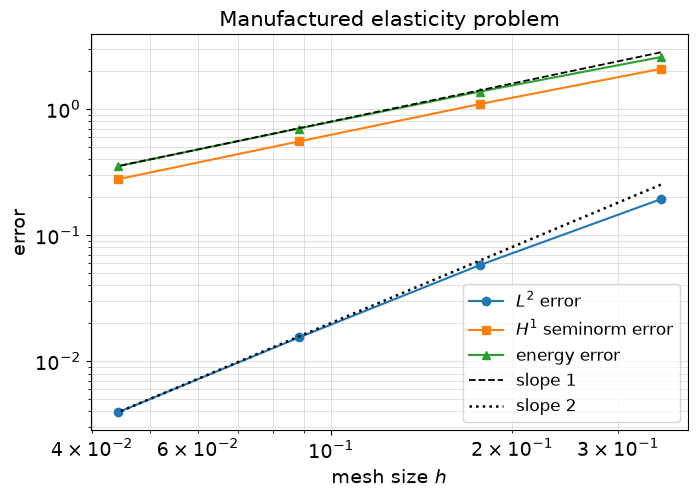

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 5.2))

ax.loglog(h_values, errors_L2, "o-", label=r"$L^2$ error")
ax.loglog(h_values, errors_H1, "s-", label=r"$H^1$ seminorm error")
ax.loglog(h_values, errors_energy, "^-", label="energy error")

slope_1 = errors_energy[-1] * (h_values / h_values[-1])
slope_2 = errors_L2[-1] * (h_values / h_values[-1]) ** 2
ax.loglog(h_values, slope_1, "k--", linewidth=1.3, label=r"slope $1$")
ax.loglog(h_values, slope_2, "k:", linewidth=1.8, label=r"slope $2$")

ax.set(xlabel=r"mesh size $h$", ylabel="error", title="Manufactured elasticity problem")
ax.grid(True, which="both", linewidth=0.5, alpha=0.55)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "elasticity-smooth-convergence.png", dpi=220)
plt.show()

The rates should approach two in $L^2$ and one in the $H^1$ seminorm and
energy norm. Coarse meshes need not lie in the asymptotic range, so the first
observed rate can differ noticeably from the prediction.

## 2. L-shaped elastic body with a reentrant corner

Now remove the lower-right quadrant from $(-1,1)^2$. Clamp the boundary
$x=-1$ and apply the traction $\boldsymbol{t}=(0,-1)$ on the boundary segment
$x=1$. The interior angle at the origin is $3\pi/2$.

The mesh is made by creating a structured triangular mesh of the square and
retaining only the elements outside the removed quadrant.

In [8]:
def create_l_shaped_mesh(n):
    square = mesh.create_rectangle(
        MPI.COMM_SELF,
        [np.array([-1.0, -1.0]), np.array([1.0, 1.0])],
        [2 * n, 2 * n],
        cell_type=mesh.CellType.triangle,
    )

    cell_dim = square.topology.dim
    cells = np.arange(
        square.topology.index_map(cell_dim).size_local, dtype=np.int32
    )
    midpoints = mesh.compute_midpoints(square, cell_dim, cells)
    removed_quadrant = (midpoints[:, 0] > 0.0) & (midpoints[:, 1] < 0.0)

    domain, _, _, _ = mesh.create_submesh(
        square, cell_dim, cells[~removed_quadrant]
    )
    return domain

The hidden cell above constructs the L-shaped mesh by removing elements from the
lower-right quadrant of a square mesh. The following function contains the
finite element calculation. Boundary tags identify the segment carrying the
traction. After the solve, a discontinuous piecewise-constant (`DG0`) field is
used only to display one strain-energy-density value on each element. The direct
solver options have the same meaning as in the manufactured problem.

In [9]:
def solve_l_shaped_elasticity(n):
    # Mesh and vector-valued P1 finite element space
    domain = create_l_shaped_mesh(n)
    V = fem.functionspace(domain, ("Lagrange", 1, (2,)))

    # Identify the clamped and loaded boundary segments
    facet_dim = domain.topology.dim - 1

    def on_clamped_boundary(X):
        return np.isclose(X[0], -1.0)

    def on_loaded_boundary(X):
        return np.isclose(X[0], 1.0)

    clamped_facets = mesh.locate_entities_boundary(
        domain, facet_dim, on_clamped_boundary
    )
    loaded_facets = mesh.locate_entities_boundary(
        domain, facet_dim, on_loaded_boundary
    )
    loaded_boundary_id = 1
    facet_tags = mesh.meshtags(
        domain,
        facet_dim,
        loaded_facets,
        np.full(len(loaded_facets), loaded_boundary_id, dtype=np.int32),
    )

    clamped_dofs = fem.locate_dofs_topological(V, facet_dim, clamped_facets)
    zero_displacement = np.zeros(2, dtype=PETSc.ScalarType)
    bc = fem.dirichletbc(zero_displacement, clamped_dofs, V)

    # Variational problem: a(u_h, v_h) = L(v_h)
    trial = ufl.TrialFunction(V)
    test = ufl.TestFunction(V)
    traction = ufl.as_vector((0.0, -1.0))

    dx = ufl.Measure("dx", domain=domain)
    ds = ufl.Measure("ds", domain=domain, subdomain_data=facet_tags)

    a = ufl.inner(stress(trial), strain(test)) * dx
    L = ufl.dot(traction, test) * ds(loaded_boundary_id)

    # Direct solution of the finite element linear system
    problem = LinearProblem(
        a,
        L,
        bcs=[bc],
        petsc_options_prefix=f"l_shaped_elasticity_{n}_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
    )
    u_h = problem.solve()

    # Global energy quantities
    compliance = fem.assemble_scalar(
        fem.form(ufl.dot(traction, u_h) * ds(loaded_boundary_id))
    ).real
    energy_norm_squared = fem.assemble_scalar(
        fem.form(ufl.inner(stress(u_h), strain(u_h)) * dx)
    ).real

    # One constant strain-energy value per element, used only for plotting
    W = fem.functionspace(domain, ("DG", 0))
    strain_energy_density = fem.Function(W)
    density_expression = 0.5 * ufl.inner(stress(u_h), strain(u_h))
    strain_energy_density.interpolate(
        fem.Expression(density_expression, W.element.interpolation_points)
    )

    return {
        "domain": domain,
        "V": V,
        "u_h": u_h,
        "W": W,
        "density": strain_energy_density,
        "h": np.sqrt(2.0) / n,
        "compliance": compliance,
        "energy norm squared": energy_norm_squared,
        "maximum density": np.max(strain_energy_density.x.array.real),
    }

### Refinement near the corner

For the finite element solution, the compliance and squared energy norm are
equal. On two successive nested meshes, Galerkin orthogonality then gives

$$
\lVert \boldsymbol{u}_h-\boldsymbol{u}_{2h}\rVert_a^2
=\ell(\boldsymbol{u}_h)-\ell(\boldsymbol{u}_{2h}).
$$

We use this identity to calculate the energy difference between successive
solutions. This is not the exact error, but its observed rate indicates whether
the smooth-solution rate is being recovered. As above, the first observed-rate
entry is blank because no preceding energy difference is available.

In [10]:
corner_n_values = [4, 8, 16, 32]
corner_solutions = [solve_l_shaped_elasticity(n) for n in corner_n_values]

corner_table = pd.DataFrame({
    "n": corner_n_values,
    "h": [result["h"] for result in corner_solutions],
    "compliance": [result["compliance"] for result in corner_solutions],
    "energy norm squared": [
        result["energy norm squared"] for result in corner_solutions
    ],
    "maximum energy density": [
        result["maximum density"] for result in corner_solutions
    ],
})

energy_identity_difference = np.max(np.abs(
    corner_table["compliance"] - corner_table["energy norm squared"]
))
print(
    "Maximum |compliance - energy norm squared|:",
    f"{energy_identity_difference:.3e}",
)

corner_h = np.array([result["h"] for result in corner_solutions])
corner_compliance = np.array([
    result["compliance"] for result in corner_solutions
])
successive_energy_difference = np.sqrt(np.diff(corner_compliance))
successive_h = corner_h[1:]
successive_energy_rates = observed_rates(
    successive_energy_difference, successive_h
)

pd.DataFrame({
    "h": successive_h,
    "successive energy difference": successive_energy_difference,
    "observed rate": successive_energy_rates,
})

Maximum |compliance - energy norm squared|: 3.304e-12


,h,successive energy difference,observed rate
0,0.176777,0.848985,NaN
1,0.088388,0.542757,0.645434
2,0.044194,0.337519,0.685337


### Displacement and strain-energy density

The plot uses the finest mesh in the table. The strain-energy density is shown
on a logarithmic color scale so that both its concentration near the reentrant
corner and its variation through the body remain visible.

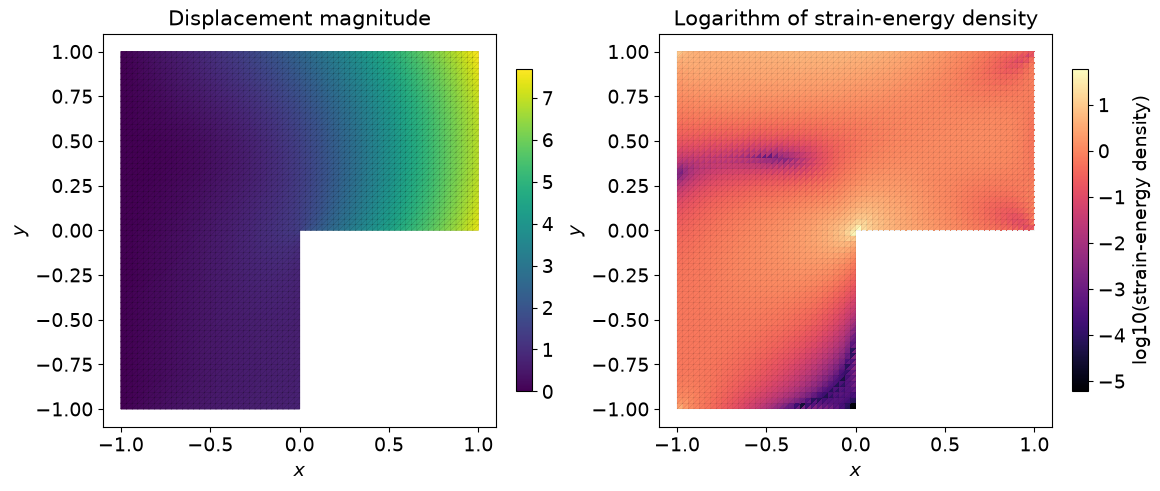

In [11]:
corner_result = corner_solutions[-1]
domain = corner_result["domain"]
u_h = corner_result["u_h"]

V_magnitude, displacement_magnitude = interpolate_scalar(
    domain, ufl.sqrt(ufl.inner(u_h, u_h))
)
triangulation = triangulation_for(V_magnitude)

W = corner_result["W"]
density = corner_result["density"]
cell_count = domain.topology.index_map(2).size_local
cell_density = np.array([
    density.x.array[W.dofmap.cell_dofs(cell)[0]].real
    for cell in range(cell_count)
])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)

displacement_plot = axes[0].tripcolor(
    triangulation,
    displacement_magnitude.x.array.real,
    shading="gouraud",
    cmap="viridis",
)
axes[0].triplot(triangulation, color="black", linewidth=0.18, alpha=0.35)
axes[0].set_title("Displacement magnitude")
fig.colorbar(displacement_plot, ax=axes[0], shrink=0.82)

log_density = np.log10(np.maximum(cell_density, 1.0e-14))
density_plot = axes[1].tripcolor(
    triangulation,
    facecolors=log_density,
    shading="flat",
    cmap="magma",
)
axes[1].triplot(triangulation, color="black", linewidth=0.15, alpha=0.25)
axes[1].set_title("Logarithm of strain-energy density")
fig.colorbar(
    density_plot,
    ax=axes[1],
    shrink=0.82,
    label="log10(strain-energy density)",
)

for ax in axes:
    ax.set(xlabel="$x$", ylabel="$y$", aspect="equal")

fig.savefig(OUTPUT_DIR / "elasticity-corner-fields.png", dpi=220)
plt.show()

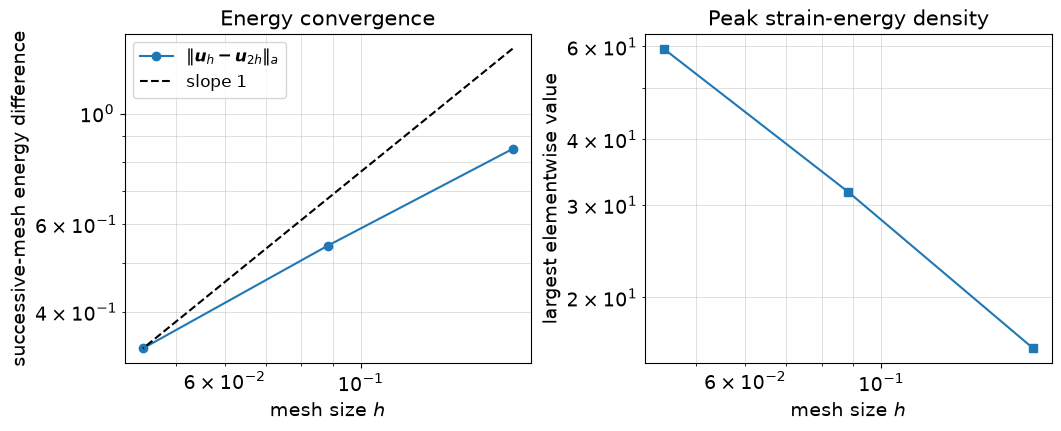

In [12]:
corner_max_density = np.array([
    result["maximum density"] for result in corner_solutions
])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)

axes[0].loglog(
    successive_h, successive_energy_difference, "o-",
    label=r"$\|\boldsymbol{u}_h-\boldsymbol{u}_{2h}\|_a$",
)
slope_1 = successive_energy_difference[-1] * (
    successive_h / successive_h[-1]
)
axes[0].loglog(successive_h, slope_1, "k--", label="slope 1")
axes[0].set(
    xlabel=r"mesh size $h$",
    ylabel="successive-mesh energy difference",
    title="Energy convergence",
)
axes[0].grid(True, which="both", linewidth=0.5, alpha=0.55)
axes[0].legend()

axes[1].loglog(successive_h, corner_max_density[1:], "s-")
axes[1].set(
    xlabel=r"mesh size $h$",
    ylabel="largest elementwise value",
    title="Peak strain-energy density",
)
axes[1].grid(True, which="both", linewidth=0.5, alpha=0.55)

fig.savefig(OUTPUT_DIR / "elasticity-corner-refinement.png", dpi=220)
plt.show()

The successive-mesh energy differences decrease with observed rates below the
first-order rate expected for a smooth solution with linear elements. At the
same time, the largest elementwise strain-energy density increases as the mesh
resolves the localized field near the corner. These results provide numerical
evidence of global energy convergence at a reduced rate together with an
increasingly concentrated local field.